<a href="https://colab.research.google.com/github/3b232106/2026_DL_hws/blob/main/hw3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 作業3 - 四資四乙 3B232106 陳威廷

## a. 資料預處理

In [23]:
from tensorflow.keras import utils   # tf 2.0
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(10)

In [24]:
from keras.datasets import fashion_mnist
(x_train_image,y_train_label),\
(x_test_image,y_test_label)= fashion_mnist.load_data()

In [25]:
x_Train = x_train_image.reshape(60000, 784).astype('float32')
x_Test = x_test_image.reshape(10000, 784).astype('float32')

In [26]:
x_Train_normalize = x_Train / 255
x_Test_normalize = x_Test / 255

In [27]:
y_Train_OneHot = utils.to_categorical(y_train_label)
y_Test_OneHot = utils.to_categorical(y_test_label)

In [28]:
# 資料類別標籤
labels_name = ["T-shirt/top(T恤)","Trouser(褲子)","Pullover(套衫)","Dress(裙子)","Coat(外套)","Sandal(涼鞋)","Shirt(汗衫)","Sneaker(運動鞋)","Bag(包)","Ankle boot(踝靴)"]

/tmp/ipykernel_3415/2572458697.py:8: UserWarning: Glyph 36381 (\N{CJK UNIFIED IDEOGRAPH-8E1D}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3415/2572458697.py:8: UserWarning: Glyph 38772 (\N{CJK UNIFIED IDEOGRAPH-9774}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3415/2572458697.py:8: UserWarning: Glyph 24676 (\N{CJK UNIFIED IDEOGRAPH-6064}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 36381 (\N{CJK UNIFIED IDEOGRAPH-8E1D}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 38772 (\N{CJK UNIFIED IDEOGRAPH-9774}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 24676 (\N{CJK UNIFIED IDEOGRAPH-6064}) missing 

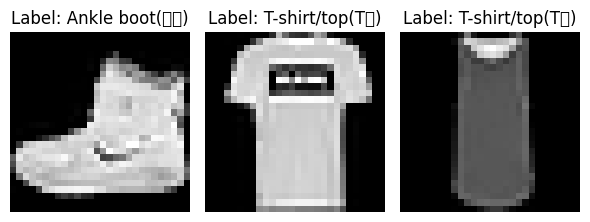

In [29]:
# 呈現訓練資料、測試資料的形狀
plt.figure(figsize=(6, 3))
for i in range(0, 3):
  plt.subplot(1, 3, i + 1)
  plt.imshow(x_train_image[i], cmap='gray')
  plt.title(f"Label: {labels_name[y_train_label[i]]}")
  plt.axis("off")
plt.tight_layout()
plt.show()

## b. 建立神經網路模型

In [30]:
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import Dropout

In [31]:
model = Sequential()

In [32]:
# 輸入層
model.add(Dense(units=256, input_dim=784, kernel_initializer='normal', activation='relu'))

# 第一隱藏層
model.add(Dense(units=128, kernel_initializer='normal', activation='relu'))

# 第二隱藏層
model.add(Dense(units=64,  kernel_initializer='normal', activation='relu'))

# 第三隱藏層
model.add(Dense(units=32,  kernel_initializer='normal', activation='relu'))

# 輸出層
model.add(Dense(units=10, kernel_initializer='normal', activation='softmax'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [33]:
print(model.summary())

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 244,522 (955.16 KB)

 Trainable params: 244,522 (955.16 KB)

 Non-trainable params: 0 (0.00 B)

None


### 神經網路模型參數計算 :
1. 輸入層 : 784 * 256 + 256 = 200960
2. 第一隱藏層 : 256 * 128 + 128 = 32896
3. 第二隱藏層 : 128 * 64 + 64 = 8256
4. 第三隱藏層 : 64 * 32 + 32 = 2080
5. 輸出層 : 32 * 10 + 10 = 330

總參數數量：200,960 + 32,896 + 8,256 + 2,080 + 330 = 244,522

## c. 訓練神經網路模型


In [34]:
model.compile(loss='categorical_crossentropy',
              optimizer='adam', metrics=['accuracy'])

## 驗證(validation)用資料
* 從訓練資料當中切出20%作為**驗證(validation)**用資料
* 全部訓練資料60000筆資料(手寫數字圖片)當中，12000筆當作驗證資料，故真正訓練資料只剩48000筆

## 批次大小(batch_size)


In [35]:
train_history =model.fit(x=x_Train_normalize,
             y=y_Train_OneHot,validation_split=0.2,
             epochs=30, batch_size=200, verbose=2)

Epoch 1/30
240/240 - 4s - 19ms/step - accuracy: 0.6809 - loss: 0.8580 - val_accuracy: 0.7899 - val_loss: 0.5717
Epoch 2/30
240/240 - 4s - 16ms/step - accuracy: 0.8271 - loss: 0.4904 - val_accuracy: 0.8466 - val_loss: 0.4400
Epoch 3/30
240/240 - 3s - 13ms/step - accuracy: 0.8517 - loss: 0.4144 - val_accuracy: 0.8496 - val_loss: 0.4245
Epoch 4/30
240/240 - 2s - 10ms/step - accuracy: 0.8633 - loss: 0.3786 - val_accuracy: 0.8604 - val_loss: 0.3923
Epoch 5/30
240/240 - 2s - 10ms/step - accuracy: 0.8737 - loss: 0.3498 - val_accuracy: 0.8669 - val_loss: 0.3644
Epoch 6/30
240/240 - 2s - 10ms/step - accuracy: 0.8799 - loss: 0.3307 - val_accuracy: 0.8777 - val_loss: 0.3498
Epoch 7/30
240/240 - 3s - 14ms/step - accuracy: 0.8847 - loss: 0.3139 - val_accuracy: 0.8799 - val_loss: 0.3357
Epoch 8/30
240/240 - 3s - 15ms/step - accuracy: 0.8914 - loss: 0.2973 - val_accuracy: 0.8826 - val_loss: 0.3312
Epoch 9/30
240/240 - 2s - 10ms/step - accuracy: 0.8963 - loss: 0.2830 - val_accuracy: 0.8810 - val_loss:

## d. 以折線圖顯示訓練過程的 loss & accuracy
* 每一epoch訓練後，計算神經網路所有批次的平均準確率(accuracy)與平均損失(loss)。
* 每一epoch訓練後，用驗證資料驗證神經網路的準確率(val_accuracy)與損失(val_loss)。

In [36]:
import matplotlib.pyplot as plt

# 畫出訓練過程每一個epoch訓練資料與驗證資料各自準確率(accuracy)的變化，或者損失誤差(loss)的變化
def show_train_history(train_history,train,validation):
    plt.plot(train_history.history[train])
    plt.plot(train_history.history[validation])
    plt.title('Train History')
    plt.ylabel(train)
    plt.xlabel('Epoch')
    plt.legend(['train', 'validation'], loc='upper left')
    plt.show()

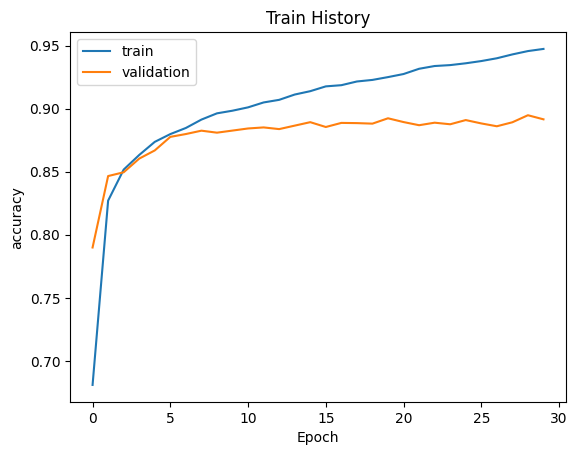

In [37]:
# 準確率(accuracy)
show_train_history(train_history,'accuracy','val_accuracy')

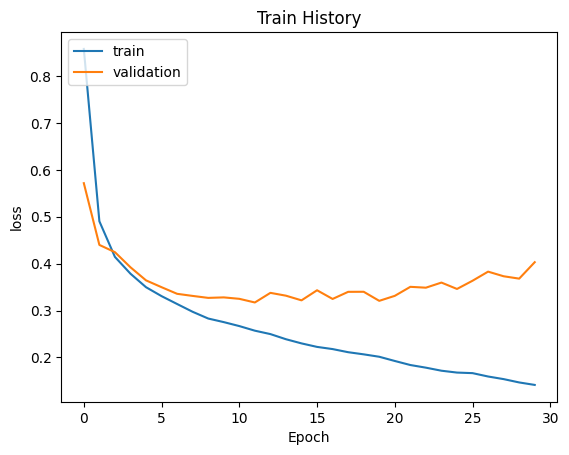

In [38]:
# 損失誤差(loss)
show_train_history(train_history,'loss','val_loss')

## e. 評估模型準確率

In [39]:
scores = model.evaluate(x_Test_normalize, y_Test_OneHot)
print()
print('accuracy=',scores[1])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8824 - loss: 0.4422

accuracy= 0.8823999762535095


## f. 進行預測

In [40]:
# 用全部測試資料，必須呈現數張測試資料(圖片)、測試資料預測的結果(標籤名稱)、與測試資料真實的標籤名稱
def plot_images_labels_prediction(images,labels,prediction,idx,num=10):
    fig = plt.gcf()
    fig.set_size_inches(12, 14)
    if num>25: num=25
    for i in range(0, num):
        ax=plt.subplot(5,5, 1+i)
        ax.imshow(images[idx], cmap='binary')
        title= "label=" +str(labels_name[labels[idx]])+"\n"
        if len(prediction)>0:
            title+="predict="+str(labels_name[np.argmax(prediction[idx])])

        ax.set_title(title,fontsize=10)
        ax.set_xticks([]);ax.set_yticks([])
        idx+=1
    plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 22871 (\N{CJK UNIFIED IDEOGRAPH-5957}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 34923 (\N{CJK UNIFIED IDEOGRAPH-886B}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 35122 (\N{CJK UNIFIED IDEOGRAPH-8932}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 23376 (\N{CJK UNIFIED IDEOGRAPH-5B50}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 27735 (\N{CJK UNIFIED IDEOGRAPH-6C57}) missing from font(s) DejaVu Sans.
  fig.canvas

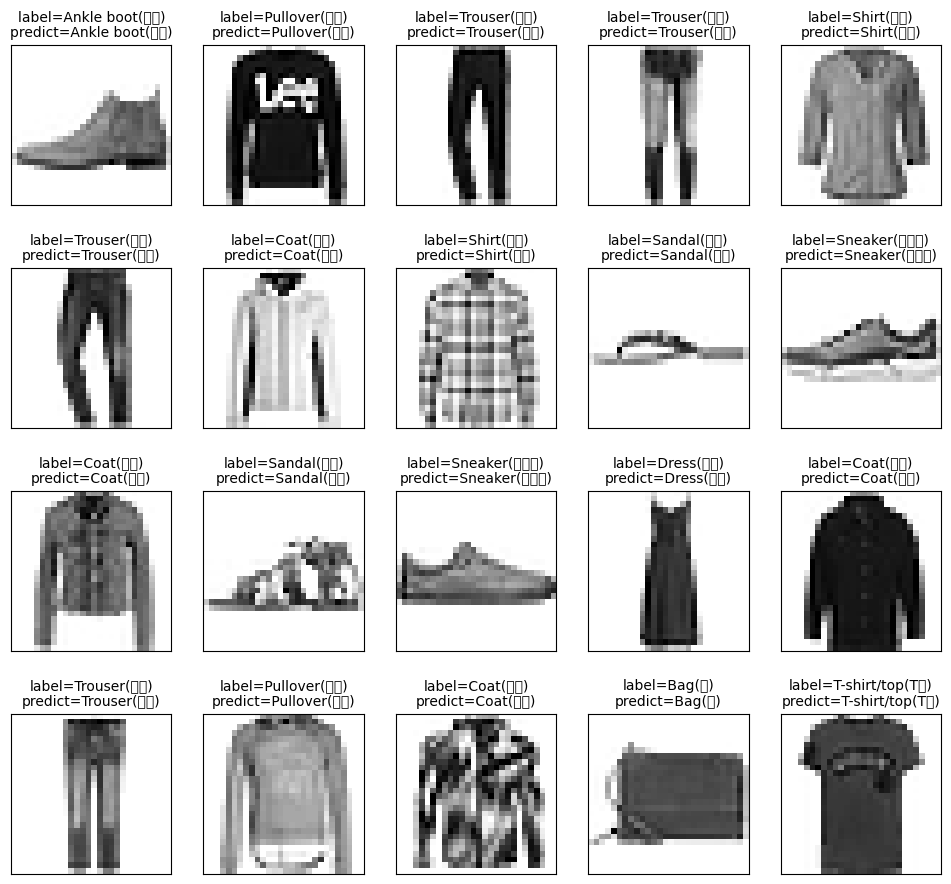

In [41]:
prediction = model.predict(x_Test)
plot_images_labels_prediction(x_test_image,y_test_label,
               prediction,idx=0,num=20)

## g. 以混淆矩陣(Confusion matrix)呈現預測結果
*   預測結果與真實結果相同或不同的情形

In [42]:
import pandas as pd
# 將10000個預測結果一一轉換為
predicted_labels = np.argmax(prediction, axis=1)

# Now use predicted_labels in crosstab
pd.crosstab(y_test_label, predicted_labels, rownames=['label'], colnames=['predict'])

predict,0,1,2,3,4,5,6,7,8,9
label,,,,,,,,,,
0,745,9,14,32,14,0,168,0,18,0
1,0,976,1,9,10,0,3,0,1,0
2,10,1,604,5,265,0,112,0,3,0
3,10,13,9,807,123,0,33,0,5,0
4,1,1,21,6,934,0,36,0,1,0
5,0,0,0,1,0,918,4,27,6,44
6,79,3,34,20,144,0,708,0,12,0
7,0,1,0,0,0,5,0,905,0,89
8,2,0,1,2,12,1,3,3,976,0


In [43]:
# 每一筆測試資料的真實結果標籤(label)與預測結果標籤(predict)的表格(df)
df = pd.DataFrame({'label': y_test_label, 'predict': predicted_labels})
df[:10] # 表格前10筆測試資料

,label,predict
0,9,9
1,2,2
2,1,1
3,1,1
4,6,6
5,1,1
6,4,4
7,6,6
8,5,5
9,7,7


##　h. 儲存完整模型

In [44]:
#儲存 model
from google.colab import drive
drive.mount('/content/drive')

%cd '/content/drive/My Drive/Colab Notebooks'

model.save('hw3.keras')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/My Drive/Colab Notebooks
